In [45]:
!pip install requests rasterio matplotlib

In [1]:
!pip install pystac-client geopandas

  Obtaining dependency information for pystac-client from https://files.pythonhosted.org/packages/5d/d2/5f6367b14c9f250d1a6725d18bd1e9584f5ab1587e292f3a847e59189598/pystac_client-0.9.0-py3-none-any.whl.metadata
  Using cached pystac_client-0.9.0-py3-none-any.whl.metadata (3.1 kB)
  Obtaining dependency information for pystac[validation]>=1.10.0 from https://files.pythonhosted.org/packages/34/54/81ca429d8ee0fa1ff78ad3102a612cfb8224aae4ba42ac625c726b13f81c/pystac-1.15.2-py3-none-any.whl.metadata
  Using cached pystac-1.15.2-py3-none-any.whl.metadata (6.3 kB)
  Obtaining dependency information for pystac-core<2,>=1.15.0 from https://files.pythonhosted.org/packages/c0/d6/3c65df53ac66532e4451917ed63dcc7c260db30eed0d5c5f1782fcc4128e/pystac_core-1.15.2-py3-none-any.whl.metadata
  Using cached pystac_core-1.15.2-py3-none-any.whl.metadata (1.3 kB)
  Obtaining dependency information for pystac-ext-classification from https://files.pythonhosted.org/packages/64/6e/a2bc64146ac5afb5a72815288ffb811a4

In [2]:
import geopandas as gpd
from pystac_client import Client

c:\Users\jazmi\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\jazmi\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [4]:
boundary = gpd.read_file("western_nc_helene.geojson")

print(boundary.crs)
print(boundary.total_bounds)

EPSG:4326
[-84.321821  34.986628 -81.363796  36.159057]


In [ ]:
# Connect to the STAC API for the Copernicus Data Space
catalog = Client.open(
    "https://stac.dataspace.copernicus.eu/v1/"
)

print("Connected!")

Connected!


In [8]:
geom = boundary.geometry.union_all().__geo_interface__

print(geom["type"])

Polygon


In [12]:
import requests

url = "https://stac.dataspace.copernicus.eu/v1/search"

data = {
    "bbox": [-84.32, 34.99, -81.36, 36.16],
    "datetime": "2023-01-01T00:00:00Z/2023-09-25T23:59:59Z",
    "collections": ["sentinel-2-l2a"],
    "limit": 10
}

response = requests.post(url, json=data)

print("Status:", response.status_code)
print("URL:", response.url)
print("Response:")
print(response.text[:1000])

Status: 200
URL: https://stac.dataspace.copernicus.eu/v1/search
Response:
{"type":"FeatureCollection","links":[{"rel":"next","type":"application/geo+json","method":"POST","href":"https://stac.dataspace.copernicus.eu/v1/search","body":{"bbox":[-84.32,34.99,-81.36,36.16],"datetime":"2023-01-01T00:00:00Z/2023-09-25T23:59:59Z","collections":["sentinel-2-l2a"],"limit":10,"token":"next:sentinel-2-l2a:S2A_MSIL2A_20230918T160921_N0510_R140_T17SLA_20241104T042207"}},{"rel":"root","type":"application/json","href":"https://stac.dataspace.copernicus.eu/v1/"},{"rel":"self","type":"application/json","href":"https://stac.dataspace.copernicus.eu/v1/search"}],"features":[{"id":"S2A_MSIL2A_20230925T160011_N0510_R097_T17SMV_20241026T172311","bbox":[-81.48779493816897,35.152409141290775,-80.89151039205204,36.14484927635336],"type":"Feature","links":[{"rel":"collection","type":"application/json","href":"https://stac.dataspace.copernicus.eu/v1/collections/sentinel-2-l2a"},{"rel":"parent","type":"application

In [13]:
results = response.json()

print("Number of results:", len(results["features"]))

for item in results["features"]:
    print(
        item["properties"].get("datetime"),
        item["id"],
        item["properties"].get("eo:cloud_cover")
    )

Number of results: 10
2023-09-25T16:00:11.024000Z S2A_MSIL2A_20230925T160011_N0510_R097_T17SMV_20241026T172311 26.27
2023-09-25T16:00:11.024000Z S2A_MSIL2A_20230925T160011_N0510_R097_T17SMU_20241026T172311 67.62
2023-09-20T15:58:49.024000Z S2B_MSIL2A_20230920T155849_N0510_R097_T17SMV_20241105T211833 83.93
2023-09-20T15:58:49.024000Z S2B_MSIL2A_20230920T155849_N0510_R097_T17SMU_20241105T211833 69.15
2023-09-18T16:09:21.024000Z S2A_MSIL2A_20230918T160921_N0510_R140_T17SMV_20241104T042207 13.95
2023-09-18T16:09:21.024000Z S2A_MSIL2A_20230918T160921_N0510_R140_T17SMU_20241104T042207 4.18
2023-09-18T16:09:21.024000Z S2A_MSIL2A_20230918T160921_N0510_R140_T17SMA_20241104T042207 48.28
2023-09-18T16:09:21.024000Z S2A_MSIL2A_20230918T160921_N0510_R140_T17SLV_20241104T042207 34.83
2023-09-18T16:09:21.024000Z S2A_MSIL2A_20230918T160921_N0510_R140_T17SLU_20241104T042207 5.26
2023-09-18T16:09:21.024000Z S2A_MSIL2A_20230918T160921_N0510_R140_T17SLA_20241104T042207 47.16


In [14]:
data = {
    "bbox": [-84.32, 34.99, -81.36, 36.16],
    "datetime": "2023-01-01T00:00:00Z/2023-09-25T23:59:59Z",
    "collections": ["sentinel-2-l2a"],
    "query": {
        "eo:cloud_cover": {
            "lte": 20
        }
    },
    "limit": 100
}

response = requests.post(url, json=data)

print("Status:", response.status_code)

results = response.json()

print("Number of results:", len(results["features"]))

Status: 200
Number of results: 100


In [16]:
count =0
for item in results["features"]:
    count +=1
    print(
        item["properties"].get("datetime"),
        "| Cloud:",
        item["properties"].get("eo:cloud_cover"),
        "| ID:",
        item["id"]
    )
print(count)

2023-09-18T16:09:21.024000Z | Cloud: 13.95 | ID: S2A_MSIL2A_20230918T160921_N0510_R140_T17SMV_20241104T042207
2023-09-18T16:09:21.024000Z | Cloud: 4.18 | ID: S2A_MSIL2A_20230918T160921_N0510_R140_T17SMU_20241104T042207
2023-09-18T16:09:21.024000Z | Cloud: 5.26 | ID: S2A_MSIL2A_20230918T160921_N0510_R140_T17SLU_20241104T042207
2023-09-18T16:09:21.024000Z | Cloud: 12.57 | ID: S2A_MSIL2A_20230918T160921_N0510_R140_T17SKU_20241104T042207
2023-09-18T16:09:21.024000Z | Cloud: 15.86 | ID: S2A_MSIL2A_20230918T160921_N0510_R140_T16SGD_20241104T042207
2023-09-15T15:59:01.024000Z | Cloud: 0.04 | ID: S2A_MSIL2A_20230915T155901_N0510_R097_T17SMV_20241103T091138
2023-09-15T15:59:01.024000Z | Cloud: 0.0 | ID: S2A_MSIL2A_20230915T155901_N0510_R097_T17SMU_20241103T091138
2023-09-11T16:18:41.024000Z | Cloud: 10.63 | ID: S2A_MSIL2A_20230911T161841_N0510_R040_T17SLV_20240915T101838
2023-09-11T16:18:41.024000Z | Cloud: 0.25 | ID: S2A_MSIL2A_20230911T161841_N0510_R040_T17SLU_20240915T101838
2023-09-11T16:18

In [17]:
from collections import defaultdict

dates = defaultdict(list)

for item in results["features"]:
    date = item["properties"]["datetime"][:10]
    cloud = item["properties"].get("eo:cloud_cover")
    tile = item["id"].split("_")[-2]

    dates[date].append((tile, cloud))

for date, tiles in sorted(dates.items()):
    print(f"\n{date}")
    for tile, cloud in tiles:
        print(f"  {tile} | Cloud: {cloud}%")


2023-06-28
  T17SLU | Cloud: 0.01%
  T17SKV | Cloud: 15.38%
  T17SKU | Cloud: 1.01%
  T16SGF | Cloud: 16.83%
  T16SGE | Cloud: 14.87%

2023-07-07
  T17SMV | Cloud: 14.12%
  T17SMU | Cloud: 13.31%

2023-07-08
  T17SLV | Cloud: 19.5%

2023-07-10
  T17SMA | Cloud: 9.17%
  T17SLA | Cloud: 16.56%
  T17SKA | Cloud: 15.61%
  T16SGF | Cloud: 15.19%

2023-07-12
  T17SMV | Cloud: 12.44%
  T17SMU | Cloud: 19.9%

2023-07-18
  T17SLV | Cloud: 1.2%
  T17SLV | Cloud: 12.34%
  T17SLU | Cloud: 15.2%
  T17SLA | Cloud: 1.19%
  T17SLA | Cloud: 0.31%
  T17SKV | Cloud: 1.4%
  T17SKV | Cloud: 14.74%
  T17SKA | Cloud: 19.12%
  T16SGE | Cloud: 3.33%

2023-07-22
  T17SMV | Cloud: 6.53%
  T17SMU | Cloud: 15.24%

2023-07-23
  T16SGF | Cloud: 16.38%

2023-07-25
  T17SMV | Cloud: 7.7%
  T17SMU | Cloud: 18.45%
  T17SLU | Cloud: 4.26%
  T17SKV | Cloud: 15.99%
  T17SKU | Cloud: 3.59%
  T16SGE | Cloud: 19.22%
  T16SGD | Cloud: 2.95%

2023-07-27
  T17SMV | Cloud: 5.39%

2023-07-28
  T17SLU | Cloud: 11.28%
  T17SKV | Cl

In [20]:
all_2023 = []

months = [
    ("2023-01-01T00:00:00Z", "2023-01-31T23:59:59Z"),
    ("2023-02-01T00:00:00Z", "2023-02-28T23:59:59Z"),
    ("2023-03-01T00:00:00Z", "2023-03-31T23:59:59Z"),
    ("2023-04-01T00:00:00Z", "2023-04-30T23:59:59Z"),
    ("2023-05-01T00:00:00Z", "2023-05-31T23:59:59Z"),
    ("2023-06-01T00:00:00Z", "2023-06-30T23:59:59Z"),
    ("2023-07-01T00:00:00Z", "2023-07-31T23:59:59Z"),
    ("2023-08-01T00:00:00Z", "2023-08-31T23:59:59Z"),
    ("2023-09-01T00:00:00Z", "2023-09-25T23:59:59Z")
]

for start, end in months:

    data = {
        "bbox": [-84.32, 34.99, -81.36, 36.16],
        "datetime": f"{start}/{end}",
        "collections": ["sentinel-2-l2a"],
        "query": {
            "eo:cloud_cover": {
                "lte": 20
            }
        },
        "limit": 100
    }

    response = requests.post(url, json=data)

    if response.status_code == 200:
        features = response.json()["features"]
        all_2023.extend(features)
        print(start[:7], ":", len(features))
    else:
        print("Error:", start[:7], response.status_code)

print("\nTotal images:", len(all_2023))

2023-01 : 31
2023-02 : 38
2023-03 : 64
2023-04 : 43
2023-05 : 44
2023-06 : 34
2023-07 : 34
2023-08 : 30
2023-09 : 31

Total images: 349


In [22]:
from collections import Counter

tile_counts = Counter()

for item in all_2023:
    tile = item["id"].split("_")[-2]
    tile_counts[tile] += 1

print("Number of unique tiles:", len(tile_counts))

for tile, count in tile_counts.most_common():
    print(tile, count)

Number of unique tiles: 12
T17SLU 44
T17SKV 34
T17SLA 33
T16SGF 32
T17SMU 31
T17SKA 31
T17SMV 29
T17SLV 28
T17SKU 28
T16SGE 28
T16SGD 23
T17SMA 8


In [23]:
for tile, count in tile_counts.most_common():
    print(f"{tile}: {count} images")

T17SLU: 44 images
T17SKV: 34 images
T17SLA: 33 images
T16SGF: 32 images
T17SMU: 31 images
T17SKA: 31 images
T17SMV: 29 images
T17SLV: 28 images
T17SKU: 28 images
T16SGE: 28 images
T16SGD: 23 images
T17SMA: 8 images


In [24]:
import geopandas as gpd
from shapely.geometry import shape

tile_geometries = {}

for item in all_2023:
    tile = item["id"].split("_")[-2]

    if tile not in tile_geometries:
        tile_geometries[tile] = shape(item["geometry"])

tiles_gdf = gpd.GeoDataFrame(
    {
        "tile": list(tile_geometries.keys()),
        "geometry": list(tile_geometries.values())
    },
    crs="EPSG:4326"
)

print(tiles_gdf)

      tile                                           geometry
0   T17SMU  POLYGON ((-81.72777 34.24954, -80.894 34.25288...
1   T17SLU  POLYGON ((-83.19754 35.22312, -83.1715 34.2336...
2   T17SLV  POLYGON ((-82.87824 36.12891, -83.2224 36.1242...
3   T17SLA  POLYGON ((-82.58199 37.03444, -83.24838 37.025...
4   T17SKV  POLYGON ((-83.09624 35.456, -83.11379 36.12624...
5   T17SKU  POLYGON ((-83.17055 35.22324, -84.29518 35.198...
6   T17SKA  POLYGON ((-84.37132 36.99867, -84.32869 36.010...
7   T16SGF  POLYGON ((-84.75207 37.02528, -84.78053 36.036...
8   T16SGE  POLYGON ((-84.77805 36.12428, -84.80527 35.135...
9   T16SGD  POLYGON ((-84.8029 35.22313, -84.82894 34.2337...
10  T17SMV  POLYGON ((-82.11193 36.13974, -82.09829 35.149...
11  T17SMA  POLYGON ((-82.12494 37.04125, -82.11068 36.051...


In [25]:
boundary = gpd.read_file("western_nc_helene.geojson").to_crs("EPSG:4326")

tiles_gdf["intersects_study_area"] = tiles_gdf.geometry.intersects(
    boundary.union_all()
)

print(
    tiles_gdf[
        tiles_gdf["intersects_study_area"]
    ]["tile"].tolist()
)

['T17SLU', 'T17SLV', 'T17SKV', 'T17SKU', 'T16SGE', 'T16SGD', 'T17SMV', 'T17SMA']


In [26]:
required_tiles = {
    "T17SLU",
    "T17SLV",
    "T17SKV",
    "T17SKU",
    "T16SGE",
    "T16SGD",
    "T17SMV",
    "T17SMA"
}

date_tile_data = {}

for item in all_2023:
    tile = item["id"].split("_")[-2]

    if tile not in required_tiles:
        continue

    date = item["properties"]["datetime"][:10]
    cloud = item["properties"].get("eo:cloud_cover")

    if date not in date_tile_data:
        date_tile_data[date] = []

    date_tile_data[date].append((tile, cloud))

for date in sorted(date_tile_data):
    tiles = date_tile_data[date]

    print(
        date,
        "| Tiles:", len(tiles),
        "| Best cloud:", min(c for _, c in tiles)
    )

2023-01-06 | Tiles: 7 | Best cloud: 0.0
2023-01-09 | Tiles: 2 | Best cloud: 0.28
2023-01-14 | Tiles: 1 | Best cloud: 7.9
2023-01-24 | Tiles: 6 | Best cloud: 0.68
2023-01-26 | Tiles: 1 | Best cloud: 10.01
2023-02-03 | Tiles: 6 | Best cloud: 0.06
2023-02-13 | Tiles: 6 | Best cloud: 0.0
2023-02-18 | Tiles: 6 | Best cloud: 3.06
2023-02-28 | Tiles: 6 | Best cloud: 0.0
2023-03-04 | Tiles: 1 | Best cloud: 0.0
2023-03-05 | Tiles: 6 | Best cloud: 0.0
2023-03-07 | Tiles: 8 | Best cloud: 0.0
2023-03-14 | Tiles: 1 | Best cloud: 7.47
2023-03-15 | Tiles: 6 | Best cloud: 0.18
2023-03-19 | Tiles: 1 | Best cloud: 1.19
2023-03-20 | Tiles: 5 | Best cloud: 7.28
2023-03-24 | Tiles: 1 | Best cloud: 0.01
2023-03-25 | Tiles: 6 | Best cloud: 0.01
2023-03-29 | Tiles: 1 | Best cloud: 6.7
2023-03-30 | Tiles: 6 | Best cloud: 0.0
2023-04-04 | Tiles: 1 | Best cloud: 0.0
2023-04-09 | Tiles: 5 | Best cloud: 0.0
2023-04-11 | Tiles: 8 | Best cloud: 0.02
2023-04-13 | Tiles: 1 | Best cloud: 10.63
2023-04-18 | Tiles: 1 | B

In [ ]:
for date in sorted(date_tile_data):

    tiles = date_tile_data[date]

    # Sort tiles by cloud cover
    tiles_sorted = sorted(tiles, key=lambda x: x[1])

    avg_cloud = sum(c for _, c in tiles) / len(tiles)

    print(
        f"{date} | "
        f"Tiles: {len(tiles)}/8 | "
        f"Avg cloud: {avg_cloud:.2f}% | "
        f"Best cloud: {tiles_sorted[0][1]:.2f}%"
    )

In [ ]:
# Create a list of dates with their coverage and average cloud
date_summary = []

for date in sorted(date_tile_data):

    tiles = date_tile_data[date]
    avg_cloud = sum(c for _, c in tiles) / len(tiles)

    date_summary.append({
        "date": date,
        "tiles": len(tiles),
        "avg_cloud": avg_cloud
    })

# Sort by most tile coverage first, then lowest cloud
date_summary_sorted = sorted(
    date_summary,
    key=lambda x: (-x["tiles"], x["avg_cloud"])
)

for x in date_summary_sorted[:20]:
    print(
        f"{x['date']} | "
        f"Tiles: {x['tiles']}/8 | "
        f"Avg cloud: {x['avg_cloud']:.2f}%"
    )

In [29]:
import requests
import pandas as pd

bbox = [-84.32, 34.99, -81.36, 36.16]

required_tiles = {
    "T17SLU",
    "T17SLV",
    "T17SKV",
    "T17SKU",
    "T16SGE",
    "T16SGD",
    "T17SMV",
    "T17SMA"
}

In [30]:
selected_dates = [
    "2023-01-06",
    "2023-02-28",
    "2023-03-07",
    "2023-04-11",
    "2023-05-09",
    "2023-06-03",
    "2023-07-18",
    "2023-09-01"
]

In [ ]:
url = "https://stac.dataspace.copernicus.eu/v1/search"

all_selected_products = []

for date in selected_dates:

    data = {
        "bbox": bbox,
        "datetime": f"{date}T00:00:00Z/{date}T23:59:59Z",
        "collections": ["sentinel-2-l2a"],
        "query": {
            "eo:cloud_cover": {
                "lte": 20
            }
        },
        "limit": 100
    }

    response = requests.post(url, json=data)
    response.raise_for_status()

    results = response.json()["features"]

    for item in results:

        tile = item["id"].split("_")[-2]

        if tile in required_tiles:

            all_selected_products.append({
                "date": date,
                "tile": tile,
                "cloud_cover": item["properties"].get("eo:cloud_cover"),
                "product_id": item["id"]
            })

products_df = pd.DataFrame(all_selected_products)

products_df

In [32]:
coverage = (
    products_df
    .groupby("date")["tile"]
    .nunique()
    .reset_index(name="tiles_found")
)

coverage

,date,tiles_found
0,2023-01-06,7
1,2023-02-28,6
2,2023-03-07,8
3,2023-04-11,8
4,2023-05-09,6
5,2023-06-03,6
6,2023-07-18,4
7,2023-09-01,4


In [ ]:
products_df = (
    products_df
    .sort_values("cloud_cover")
    .drop_duplicates(
        subset=["date", "tile"],
        keep="first"
    )
    .sort_values(["date", "tile"])
    .reset_index(drop=True)
)

products_df

In [36]:
import pandas as pd

all_2023_df = pd.DataFrame([
    {
        "date": item["properties"]["datetime"][:10],
        "tile": item["id"].split("_")[-2],
        "cloud_cover": item["properties"].get("eo:cloud_cover"),
        "product_id": item["id"]
    }
    for item in all_2023
])

all_2023_df.head()

,date,tile,cloud_cover,product_id
0,2023-01-28,T17SMU,12.34,S2A_MSIL2A_20230128T160521_N0510_R097_T17SMU_2...
1,2023-01-26,T17SMU,1.65,S2B_MSIL2A_20230126T161539_N0510_R140_T17SMU_2...
2,2023-01-26,T17SLU,10.01,S2B_MSIL2A_20230126T161539_N0510_R140_T17SLU_2...
3,2023-01-24,T17SLV,2.43,S2A_MSIL2A_20230124T162551_N0510_R040_T17SLV_2...
4,2023-01-24,T17SLU,2.15,S2A_MSIL2A_20230124T162551_N0510_R040_T17SLU_2...


In [39]:
product = products_df[
    (products_df["date"] == "2023-04-11") &
    (products_df["tile"] == "T17SLU")
]

print(product["product_id"].iloc[0])

S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750


In [40]:
import requests

product_id = product["product_id"].iloc[0]

url = (
    "https://stac.dataspace.copernicus.eu/v1/"
    f"collections/sentinel-2-l2a/items/{product_id}"
)

response = requests.get(url)
response.raise_for_status()

item = response.json()

print(item["id"])
print(item["properties"])

S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750
{'gsd': 10, 'created': '2025-01-17T06:35:44.113000Z', 'expires': '2262-01-01T00:00:00.000000Z', 'updated': '2026-04-01T05:12:00.408600Z', '_private': {'visible': True, 'product_name': 'S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750.SAFE', 'product_size': 1196450932, 'product_uuid': '08c5f805-4c6b-4a71-bdc7-f80ddf9ccb9c'}, 'datetime': '2023-04-11T16:08:31.024000Z', 'platform': 'sentinel-2a', 'grid:code': 'MGRS-17SLU', 'published': '2025-02-06T09:36:01.534447Z', 'statistics': {'water': 3.048613, 'nodata': 3e-06, 'dark_area': 0.290845, 'vegetation': 87.569785, 'thin_cirrus': 1.250669, 'cloud_shadow': 0.000382, 'unclassified': 0.307497, 'not_vegetated': 7.500282999999999, 'high_proba_clouds': 0.009565, 'medium_proba_clouds': 0.02218, 'saturated_defective': 0.0}, 'instruments': ['msi'], 'auth:schemes': {'s3': {'type': 's3'}, 'oidc': {'type': 'openIdConnect', 'openIdConnectUrl': 'https://identity.dataspace.copernicus.

In [41]:
print(item["assets"].keys())

dict_keys(['AOT_10m', 'AOT_20m', 'AOT_60m', 'B01_20m', 'B01_60m', 'B02_10m', 'B02_20m', 'B02_60m', 'B03_10m', 'B03_20m', 'B03_60m', 'B04_10m', 'B04_20m', 'B04_60m', 'B05_20m', 'B05_60m', 'B06_20m', 'B06_60m', 'B07_20m', 'B07_60m', 'B08_10m', 'B09_60m', 'B11_20m', 'B11_60m', 'B12_20m', 'B12_60m', 'B8A_20m', 'B8A_60m', 'CLD_20m', 'CLD_60m', 'Product', 'SCL_20m', 'SCL_60m', 'SNW_20m', 'SNW_60m', 'TCI_10m', 'TCI_20m', 'TCI_60m', 'WVP_10m', 'WVP_20m', 'WVP_60m', 'thumbnail', 'safe_manifest', 'granule_metadata', 'inspire_metadata', 'product_metadata', 'datastrip_metadata'])


In [ ]:
for band in ["B02_10m", "B03_10m", "B04_10m", "B08_10m", "B11_20m", "B12_20m", "SCL_20m"]:
    print(band)
    print(item["assets"][band]["href"])
    print()

In [43]:
for band in ["B02_10m", "B03_10m", "B04_10m", "B08_10m"]:
    asset = item["assets"][band]

    print("=" * 60)
    print(band)
    print("Title:", asset.get("title"))
    print("Type:", asset.get("type"))
    print("Href:", asset["href"])

B02_10m
Title: Blue (band 2) - 10m
Type: image/jp2
Href: s3://eodata/Sentinel-2/MSI/L2A_N0500/2023/04/11/S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750.SAFE/GRANULE/L2A_T17SLU_A040749_20230411T162006/IMG_DATA/R10m/T17SLU_20230411T160831_B02_10m.jp2
B03_10m
Title: Green (band 3) - 10m
Type: image/jp2
Href: s3://eodata/Sentinel-2/MSI/L2A_N0500/2023/04/11/S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750.SAFE/GRANULE/L2A_T17SLU_A040749_20230411T162006/IMG_DATA/R10m/T17SLU_20230411T160831_B03_10m.jp2
B04_10m
Title: Red (band 4) - 10m
Type: image/jp2
Href: s3://eodata/Sentinel-2/MSI/L2A_N0500/2023/04/11/S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750.SAFE/GRANULE/L2A_T17SLU_A040749_20230411T162006/IMG_DATA/R10m/T17SLU_20230411T160831_B04_10m.jp2
B08_10m
Title: NIR 1 (band 8) - 10m
Type: image/jp2
Href: s3://eodata/Sentinel-2/MSI/L2A_N0500/2023/04/11/S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750.SAFE/GRANULE/L2A_T17SLU_A040749_20230411T162

In [44]:
print(item["assets"]["B04_10m"])

{'href': 's3://eodata/Sentinel-2/MSI/L2A_N0500/2023/04/11/S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750.SAFE/GRANULE/L2A_T17SLU_A040749_20230411T162006/IMG_DATA/R10m/T17SLU_20230411T160831_B04_10m.jp2', 'bands': [{'name': 'B04', 'description': 'Red (band 4)', 'eo:common_name': 'red', 'eo:center_wavelength': 0.665, 'eo:full_width_half_max': 0.342}], 'roles': ['data', 'reflectance', 'sampling:original', 'gsd:10m'], 'alternate': {'https': {'href': 'https://download.dataspace.copernicus.eu/odata/v1/Products(08c5f805-4c6b-4a71-bdc7-f80ddf9ccb9c)/Nodes(S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750.SAFE)/Nodes(GRANULE)/Nodes(L2A_T17SLU_A040749_20230411T162006)/Nodes(IMG_DATA)/Nodes(R10m)/Nodes(T17SLU_20230411T160831_B04_10m.jp2)/$value', 'auth:refs': ['oidc'], 'storage:refs': [], 'alternate:name': 'HTTPS'}}, 'auth:refs': ['s3'], 'file:size': 125637252, 'proj:bbox': [300000, 3790200, 409800, 3900000], 'proj:code': 'EPSG:32617', 'storage:refs': ['cdse-s3', 'creodia

In [46]:
import requests
import getpass

username = input("Copernicus username: ")
password = getpass.getpass("Copernicus password: ")

auth_url = (
    "https://identity.dataspace.copernicus.eu/"
    "auth/realms/CDSE/protocol/openid-connect/token"
)

data = {
    "client_id": "cdse-public",
    "username": username,
    "password": password,
    "grant_type": "password"
}

response = requests.post(auth_url, data=data)
response.raise_for_status()

access_token = response.json()["access_token"]

print("Login successful!")

Login successful!


In [47]:
product_name = products_df[
    (products_df["date"] == "2023-04-11") &
    (products_df["tile"] == "T17SLU")
]["product_id"].iloc[0]

print(product_name)

S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750


In [49]:
import requests

product_name = products_df[
    (products_df["date"] == "2023-04-11") &
    (products_df["tile"] == "T17SLU")
]["product_id"].iloc[0]

print("Product from STAC:")
print(product_name)

# Search Copernicus OData using the beginning of the product name
odata_url = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"

params = {
    "$filter": f"startswith(Name,'{product_name}')"
}

response = requests.get(odata_url, params=params)

print("Status:", response.status_code)

response.raise_for_status()

result = response.json()["value"]

print("Products found:", len(result))

if len(result) > 0:
    print("Name:", result[0]["Name"])
    print("UUID:", result[0]["Id"])
    print("S3 Path:", result[0]["S3Path"])

Product from STAC:
S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750
Status: 200
Products found: 1
Name: S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750.SAFE
UUID: 08c5f805-4c6b-4a71-bdc7-f80ddf9ccb9c
S3 Path: /eodata/Sentinel-2/MSI/L2A_N0500/2023/04/11/S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750.SAFE


In [50]:
import requests
import os

uuid = result[0]["Id"]

download_url = f"https://download.dataspace.copernicus.eu/odata/v1/Products({uuid})/$value"

headers = {
    "Authorization": f"Bearer {access_token}"
}

output_file = "S2A_20230411_T17SLU.zip"

response = requests.get(
    download_url,
    headers=headers,
    stream=True
)

print("Status:", response.status_code)

response.raise_for_status()

with open(output_file, "wb") as f:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            f.write(chunk)

print("Download complete!")
print("Saved as:", output_file)

Status: 200
Download complete!
Saved as: S2A_20230411_T17SLU.zip


In [52]:
extract_dir = "S2A_20230411_T17SLU"


In [56]:
import os
import glob

# Find the folder you extracted
print("Extracted folder:")
print(os.listdir(extract_dir))

Extracted folder:
['S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750.SAFE']


In [64]:
import zipfile
import os

zip_file = "S2A_20230411_T17SLU.zip"

with zipfile.ZipFile(zip_file, "r") as z:
    names = z.namelist()

needed = {}

for name in names:
    filename = os.path.basename(name)

    if filename.endswith("_B02_10m.jp2"):
        needed["B02"] = name
    elif filename.endswith("_B03_10m.jp2"):
        needed["B03"] = name
    elif filename.endswith("_B04_10m.jp2"):
        needed["B04"] = name
    elif filename.endswith("_B08_10m.jp2"):
        needed["B08"] = name
    elif filename.endswith("_SCL_20m.jp2"):
        needed["SCL"] = name

for band, path in needed.items():
    print(band, "→", path)

B02 → S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750.SAFE/GRANULE/L2A_T17SLU_A040749_20230411T162006/IMG_DATA/R10m/T17SLU_20230411T160831_B02_10m.jp2
B03 → S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750.SAFE/GRANULE/L2A_T17SLU_A040749_20230411T162006/IMG_DATA/R10m/T17SLU_20230411T160831_B03_10m.jp2
B04 → S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750.SAFE/GRANULE/L2A_T17SLU_A040749_20230411T162006/IMG_DATA/R10m/T17SLU_20230411T160831_B04_10m.jp2
B08 → S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750.SAFE/GRANULE/L2A_T17SLU_A040749_20230411T162006/IMG_DATA/R10m/T17SLU_20230411T160831_B08_10m.jp2
SCL → S2A_MSIL2A_20230411T160831_N0510_R140_T17SLU_20240827T130750.SAFE/GRANULE/L2A_T17SLU_A040749_20230411T162006/IMG_DATA/R20m/T17SLU_20230411T160831_SCL_20m.jp2


In [65]:
import os
import zipfile

image_folder = "sentinel_images"
os.makedirs(image_folder, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as z:
    for band, path in needed.items():
        output_path = os.path.join(
            image_folder,
            os.path.basename(path)
        )

        with z.open(path) as source, open(output_path, "wb") as target:
            target.write(source.read())

        print("Extracted:", output_path)

Extracted: sentinel_images\T17SLU_20230411T160831_B02_10m.jp2
Extracted: sentinel_images\T17SLU_20230411T160831_B03_10m.jp2
Extracted: sentinel_images\T17SLU_20230411T160831_B04_10m.jp2
Extracted: sentinel_images\T17SLU_20230411T160831_B08_10m.jp2
Extracted: sentinel_images\T17SLU_20230411T160831_SCL_20m.jp2


In [66]:
import rasterio

for band, path in needed.items():
    filename = os.path.join(
        image_folder,
        os.path.basename(path)
    )

    with rasterio.open(filename) as src:
        print(
            band,
            "shape:", src.shape,
            "CRS:", src.crs
        )

B02 shape: (10980, 10980) CRS: EPSG:32617
B03 shape: (10980, 10980) CRS: EPSG:32617
B04 shape: (10980, 10980) CRS: EPSG:32617
B08 shape: (10980, 10980) CRS: EPSG:32617
SCL shape: (5490, 5490) CRS: EPSG:32617


In [ ]:
import rasterio
import os
# CLIPPED WITH BAND 4 and 8
def load_band(band):
    path = os.path.join(
        image_folder,
        os.path.basename(needed[band])
    )
    
    with rasterio.open(path) as src:
        return src.read(1), src.profile

b02, profile = load_band("B02")
b03, _ = load_band("B03")
b04, _ = load_band("B04")
b08, _ = load_band("B08")

print("B02:", b02.shape)
print("B03:", b03.shape)
print("B04:", b04.shape)
print("B08:", b08.shape)

B02: (10980, 10980)
B03: (10980, 10980)
B04: (10980, 10980)
B08: (10980, 10980)


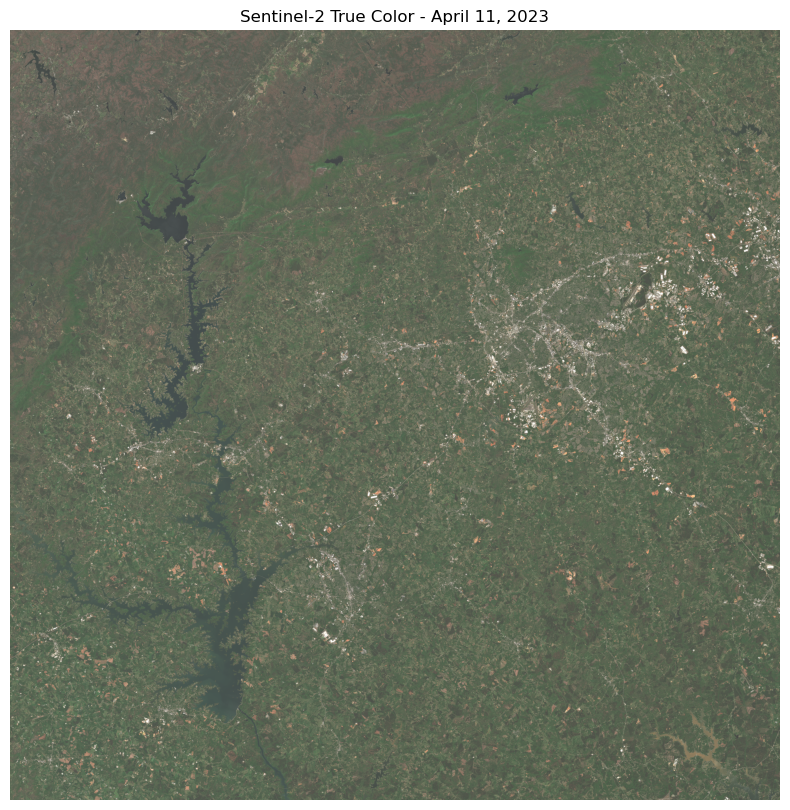

In [69]:
import numpy as np
import matplotlib.pyplot as plt

red = b04.astype(float) / 10000
green = b03.astype(float) / 10000
blue = b02.astype(float) / 10000

rgb = np.dstack([red, green, blue])

plt.figure(figsize=(10, 10))
plt.imshow(np.clip(rgb * 2.5, 0, 1))
plt.title("Sentinel-2 True Color - April 11, 2023")
plt.axis("off")
plt.show()

In [71]:
denominator = b08.astype(float) + b04.astype(float)

ndvi = np.divide(
    b08.astype(float) - b04.astype(float),
    denominator,
    out=np.zeros_like(denominator),
    where=denominator != 0
)

print("NDVI minimum:", np.nanmin(ndvi))
print("NDVI maximum:", np.nanmax(ndvi))
print("NDVI mean:", np.nanmean(ndvi))

NDVI minimum: -0.605879650895728
NDVI maximum: 0.7730739299610895
NDVI mean: 0.40027605410545436


In [73]:
valid = (b04 > 0) & (b08 > 0)

ndvi_valid = ndvi[valid]

print("Valid NDVI minimum:", ndvi_valid.min())
print("Valid NDVI maximum:", ndvi_valid.max())
print("Valid NDVI mean:", ndvi_valid.mean())
print("Valid pixels:", len(ndvi_valid))

Valid NDVI minimum: -0.605879650895728
Valid NDVI maximum: 0.7730739299610895
Valid NDVI mean: 0.4002760673859693
Valid pixels: 120560396


In [72]:
print("B04 range:", b04.min(), "to", b04.max())
print("B08 range:", b08.min(), "to", b08.max())
print("NDVI range:", ndvi.min(), "to", ndvi.max())

B04 range: 0 to 17088
B08 range: 0 to 16528
NDVI range: -0.605879650895728 to 0.7730739299610895


Now, going to clip it to the boundary of 17 counties for western north carolina region using GEDI pretrained geojson data

In [74]:
boundary = boundary.to_crs(profile["crs"])

print("Boundary CRS:", boundary.crs)
print("Sentinel-2 CRS:", profile["crs"])

Boundary CRS: PROJCS["WGS 84 / UTM zone 17N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-81],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32617"]]
Sentinel-2 CRS: EPSG:32617


In [75]:
from rasterio.mask import mask

boundary_shapes = [geom for geom in boundary.geometry]

with rasterio.open(
    os.path.join(image_folder, os.path.basename(needed["B04"]))
) as src:
    b04_clip, clip_transform = mask(
        src,
        boundary_shapes,
        crop=True
    )

with rasterio.open(
    os.path.join(image_folder, os.path.basename(needed["B08"]))
) as src:
    b08_clip, _ = mask(
        src,
        boundary_shapes,
        crop=True
    )

b04_clip = b04_clip[0]
b08_clip = b08_clip[0]

print("Original shape:", b04.shape)
print("Clipped shape:", b04_clip.shape)

Original shape: (10980, 10980)
Clipped shape: (2530, 10980)


In [76]:
b04_float = b04_clip.astype(float)
b08_float = b08_clip.astype(float)

denominator = b08_float + b04_float

ndvi_clip = np.divide(
    b08_float - b04_float,
    denominator,
    out=np.zeros_like(denominator),
    where=denominator != 0
)

print("Clipped NDVI minimum:", np.nanmin(ndvi_clip))
print("Clipped NDVI maximum:", np.nanmax(ndvi_clip))
print("Clipped NDVI mean:", np.nanmean(ndvi_clip))

Clipped NDVI minimum: -0.29571106094808125
Clipped NDVI maximum: 0.7162325530278053
Clipped NDVI mean: 0.16537353622660947


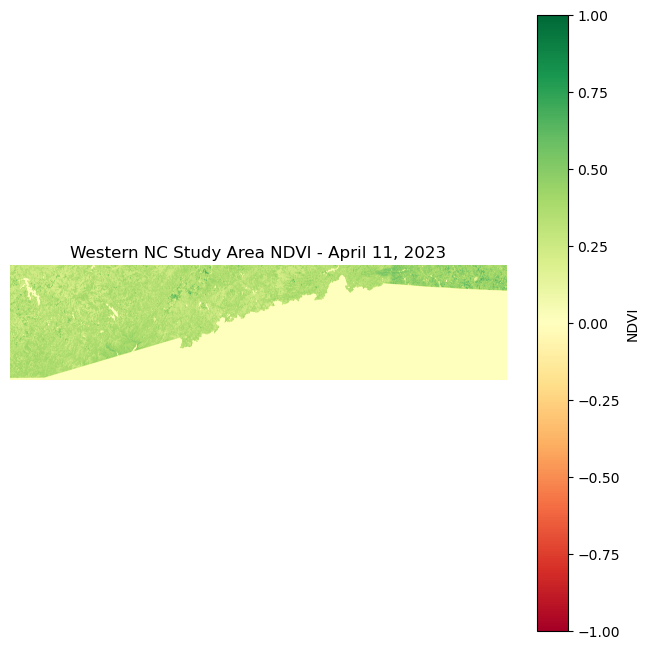

In [77]:
plt.figure(figsize=(8, 8))

plt.imshow(
    ndvi_clip,
    vmin=-1,
    vmax=1,
    cmap="RdYlGn"
)

plt.colorbar(label="NDVI")
plt.title("Western NC Study Area NDVI - April 11, 2023")
plt.axis("off")
plt.show()

In [79]:
with rasterio.open(
    os.path.join(image_folder, os.path.basename(needed["B02"]))
) as src:
    b02_clip, _ = mask(
        src,
        boundary_shapes,
        crop=True
    )

with rasterio.open(
    os.path.join(image_folder, os.path.basename(needed["B03"]))
) as src:
    b03_clip, _ = mask(
        src,
        boundary_shapes,
        crop=True
    )

b02_clip = b02_clip[0]
b03_clip = b03_clip[0]

print("B02 clipped shape:", b02_clip.shape)
print("B03 clipped shape:", b03_clip.shape)
print("B04 clipped shape:", b04_clip.shape)

B02 clipped shape: (2530, 10980)
B03 clipped shape: (2530, 10980)
B04 clipped shape: (2530, 10980)


In [81]:
from rasterio.features import geometry_mask

with rasterio.open(
    os.path.join(image_folder, os.path.basename(needed["B04"]))
) as src:
    transform = src.transform

county_mask = geometry_mask(
    boundary_shapes,
    transform=clip_transform,
    invert=True,
    out_shape=b04_clip.shape
)

c:\Users\jazmi\anaconda3\Lib\site-packages\matplotlib\cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


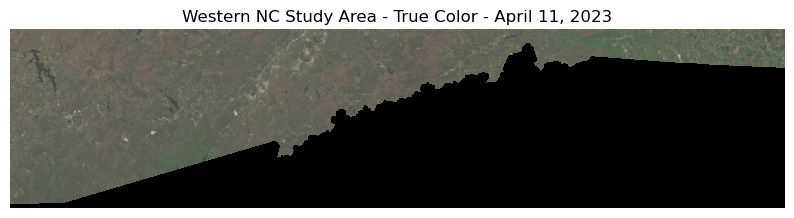

In [82]:
red = b04_clip.astype(float) / 10000
green = b03_clip.astype(float) / 10000
blue = b02_clip.astype(float) / 10000

rgb_clip = np.dstack([red, green, blue])

# Make pixels outside the counties transparent
rgb_clip[~county_mask] = np.nan

plt.figure(figsize=(10, 10))

plt.imshow(np.clip(rgb_clip * 2.5, 0, 1))

plt.title("Western NC Study Area - True Color - April 11, 2023")
plt.axis("off")
plt.show()

In [84]:
print("Number of counties:", len(boundary))

Number of counties: 17
